In [81]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt


# current features
- Daily Returns
- 20 day Sign Persistance
- 20 day Rolling Volitilty
- Moving average Trend


In [82]:
nifty_index=pd.read_csv('nifty_index.csv')


In [83]:
def returns(nifty_index):
    daily_returns = nifty_index["Close"].pct_change()
    return daily_returns


In [84]:
daily_returns=returns(nifty_index)

In [85]:
def sign_persistence(daily_returns):
    signs = np.sign(daily_returns)
    same_sign = signs.eq(signs.shift(1))
    valid_pairs = (
        signs.notna() & signs.shift(1).notna() &
        signs.ne(0) & signs.shift(1).ne(0)
    )
    window=20

    matches = (same_sign & valid_pairs).rolling(window).sum()
    valid_counts = valid_pairs.rolling(window).sum()

    sign_persistence = matches / valid_counts.replace(0, np.nan)
    return sign_persistence

sign_persistence=sign_persistence(daily_returns)

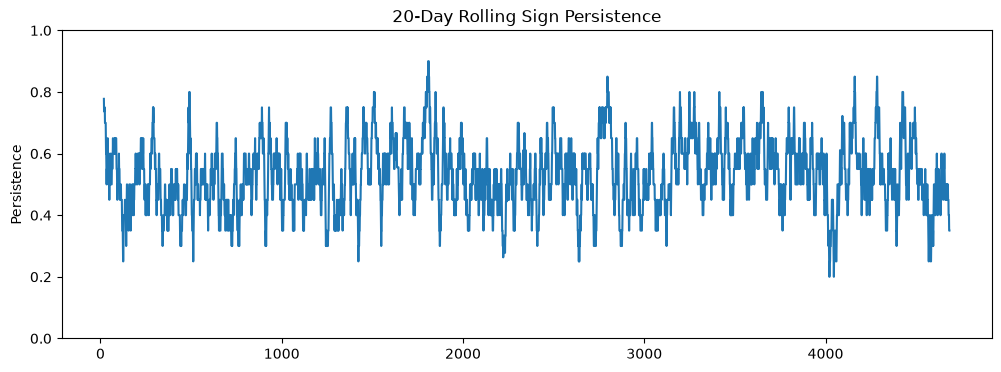

In [86]:
window=20
plt.figure(figsize=(12, 4))
plt.plot(sign_persistence)
plt.title(f"{window}-Day Rolling Sign Persistence")
plt.ylabel("Persistence")
plt.ylim(0, 1)
plt.show()

In [87]:
def rolling_volatility(daily_returns):
    return daily_returns.rolling(window=20).std()

rolling_volatility=rolling_volatility(daily_returns)

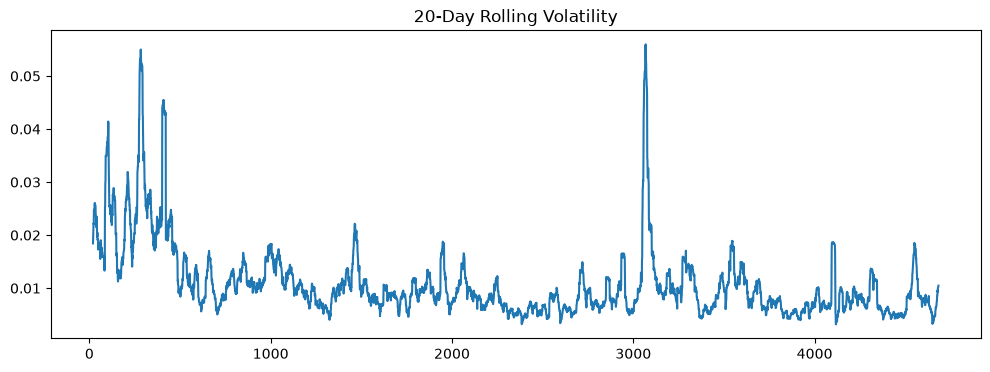

In [88]:
plt.figure(figsize=(12, 4))

plt.plot(rolling_volatility)
plt.title("20-Day Rolling Volatility")
plt.show()

In [89]:
def trend(nifty_index):
    SMA_20 = nifty_index["Close"].rolling(window=20).mean()
    SMA_50 = nifty_index["Close"].rolling(window=50).mean()
    trend = (SMA_20 - SMA_50) / SMA_50
    return trend


trend=trend(nifty_index)

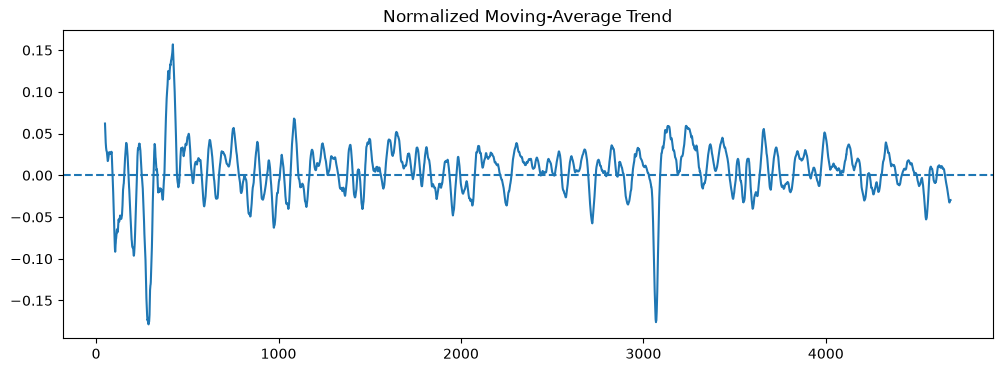

In [90]:
plt.figure(figsize=(12, 4))
plt.plot(trend)
plt.title("Normalized Moving-Average Trend")
plt.axhline(0, linestyle="--")
plt.show()

In [91]:
features=pd.concat([daily_returns,sign_persistence,rolling_volatility,trend],axis=1)
features=features.dropna(axis=0)
features.columns=["daily_returns","sign_persistence","rolling_volatility","trend"]
features

,daily_returns,sign_persistence,rolling_volatility,trend
49,-0.005853,0.45,0.017276,0.062023
50,-0.014145,0.50,0.017475,0.055358
51,0.003035,0.50,0.017429,0.048744
52,0.022743,0.55,0.018264,0.043876
53,0.017743,0.60,0.018544,0.039046
...,...,...,...,...
4679,-0.004368,0.40,0.009279,-0.031892
4680,0.016561,0.40,0.010026,-0.031031
4681,0.006470,0.40,0.010128,-0.030079
4682,-0.011112,0.35,0.010375,-0.029610


In [92]:
split_idx = int(len(features) * 0.8)
train_df=features.iloc[:split_idx]
test_df=features.iloc[split_idx:]
print(len(train_df))
print(len(test_df))
print(train_df.iloc[0])
print(train_df.iloc[-1])
print(test_df.iloc[0])
print(test_df.iloc[-1])

3708
927
daily_returns        -0.005853
sign_persistence      0.450000
rolling_volatility    0.017276
trend                 0.062023
Name: 49, dtype: float64
daily_returns         0.005510
sign_persistence      0.450000
rolling_volatility    0.008049
trend                -0.011906
Name: 3756, dtype: float64
daily_returns        -0.003439
sign_persistence      0.450000
rolling_volatility    0.007772
trend                -0.013103
Name: 3757, dtype: float64
daily_returns        -0.008795
sign_persistence      0.350000
rolling_volatility    0.010477
trend                -0.029601
Name: 4683, dtype: float64


In [93]:
means=train_df.mean()
%store means
standard_deviations=train_df.std()
%store standard_deviations

Stored 'means' (Series)
Stored 'standard_deviations' (Series)


In [94]:
train_df=train_df-means
train_df=train_df/standard_deviations
train_df

,daily_returns,sign_persistence,rolling_volatility,trend
49,-0.455438,-0.743443,0.769575,1.620613
50,-1.059074,-0.278337,0.796663,1.431343
51,0.191670,-0.278337,0.790427,1.243525
52,1.626462,0.186769,0.903954,1.105299
53,1.262444,0.651875,0.942033,0.968136
...,...,...,...,...
3752,0.956166,-0.278337,-0.429158,-0.318780
3753,-0.781593,-0.743443,-0.419327,-0.369572
3754,-0.104280,-0.743443,-0.428544,-0.421204
3755,-0.181850,-0.278337,-0.484529,-0.457500


In [95]:
print(means)
print(standard_deviations)


daily_returns         0.000402
sign_persistence      0.529922
rolling_volatility    0.011616
trend                 0.004954
dtype: float64
daily_returns         0.013736
sign_persistence      0.107502
rolling_volatility    0.007355
trend                 0.035214
dtype: float64


In [96]:
test_df=test_df-means
test_df=test_df/standard_deviations
test_df.to_csv('test_df.csv')
test_df


,daily_returns,sign_persistence,rolling_volatility,trend
3757,-0.279650,-0.743443,-0.522667,-0.512775
3758,0.615332,-0.743443,-0.477817,-0.533969
3759,0.422552,-0.743443,-0.499519,-0.536845
3760,-0.259740,-1.208548,-0.501980,-0.540798
3761,-0.351733,-1.208548,-0.647877,-0.513784
...,...,...,...,...
4679,-0.347296,-1.208548,-0.317809,-1.046352
4680,1.176360,-1.208548,-0.216240,-1.021895
4681,0.441756,-1.208548,-0.202262,-0.994848
4682,-0.838273,-1.673654,-0.168673,-0.981542


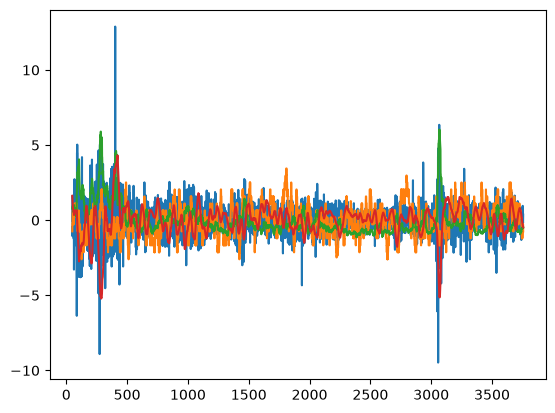

In [97]:
plt.plot(train_df)

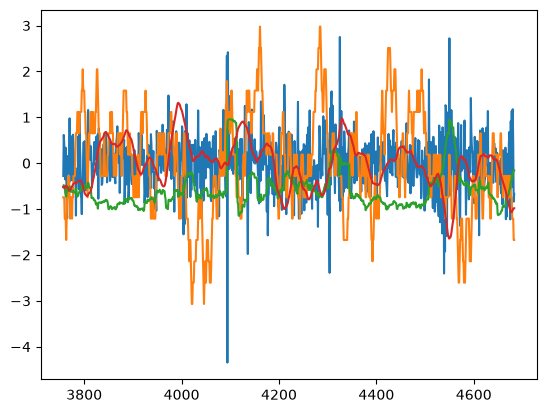

In [98]:
plt.plot(test_df)

In [99]:
train_df['trend'].corr(train_df['rolling_volatility'])


np.float64(-0.4641180605931689)

In [100]:
train_df.to_csv('train_df.csv')
test_df.to_csv('test_df.csv')

In [101]:

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)

print("Train indices:", train_df.index.min(), train_df.index.max())
print("Test indices:", test_df.index.min(), test_df.index.max())


Train shape: (3708, 4)
Test shape: (927, 4)
Train indices: 49 3756
Test indices: 3757 4683


In [102]:
X = features.copy()

X = X.replace([float("inf"), float("-inf")], float("nan")).dropna()

split_idx = int(len(X) * 0.8)
train_raw = X.iloc[:split_idx].copy()
test_raw = X.iloc[split_idx:].copy()

means = train_raw.mean()
standard_deviations = train_raw.std().replace(0, 1)

train_df = (train_raw - means) / standard_deviations
test_df = (test_raw - means) / standard_deviations

train_df.to_csv("train_df.csv")
test_df.to_csv("test_df.csv")

means.to_csv("feature_means.csv", header=["mean"])
standard_deviations.to_csv(
    "feature_standard_deviations.csv",
    header=["std"]
)

print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("Train indices:", train_df.index.min(), train_df.index.max())
print("Test indices:", test_df.index.min(), test_df.index.max())

print("\nTraining means:")
print(train_df.mean().round(6))

print("\nTraining standard deviations:")
print(train_df.std().round(6))

print("\nTest means:")
print(test_df.mean().round(6))


Train shape: (3708, 4)
Test shape: (927, 4)
Train indices: 49 3756
Test indices: 3757 4683

Training means:
daily_returns        -0.0
sign_persistence      0.0
rolling_volatility   -0.0
trend                 0.0
dtype: float64

Training standard deviations:
daily_returns         1.0
sign_persistence      1.0
rolling_volatility    1.0
trend                 1.0
dtype: float64

Test means:
daily_returns        -0.008594
sign_persistence      0.006087
rolling_volatility   -0.571015
trend                -0.029571
dtype: float64


In [103]:

train = pd.read_csv("train_df.csv", index_col=0)
test = pd.read_csv("test_df.csv", index_col=0)

print("Train/Test shapes:", train.shape, test.shape)
print("Train index:", train.index.min(), train.index.max())
print("Test index:", test.index.min(), test.index.max())

print("\nTrain means:")
print(train.mean().round(6))

print("\nTrain standard deviations:")
print(train.std().round(6))

print("\nTest first and last indices:", test.index[0], test.index[-1])


Train/Test shapes: (3708, 4) (927, 4)
Train index: 49 3756
Test index: 3757 4683

Train means:
daily_returns        -0.0
sign_persistence      0.0
rolling_volatility   -0.0
trend                 0.0
dtype: float64

Train standard deviations:
daily_returns         1.0
sign_persistence      1.0
rolling_volatility    1.0
trend                 1.0
dtype: float64

Test first and last indices: 3757 4683
